# Argentina: Capítulo IV well data and Vaca Muerta

Argentina's Secretaría de Energía publishes monthly production per well
("Capítulo IV"). `fetch` resolves the per-year CSV through the portal's CKAN
API — no hardcoded file URL. Full-year files run 100–300 MB, so this notebook
reuses an already-downloaded file when one exists.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import ogprod

# Categorical palette in fixed slot order (colorblind-safe adjacency)
PALETTE = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.axisbelow": True,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "lines.linewidth": 2,
    "figure.figsize": (9, 4),
    "font.size": 11,
})

DATA = Path("../data")
DATA.mkdir(exist_ok=True)

In [2]:
existing = sorted(DATA.glob("*2026*.csv"))
path = existing[0] if existing else ogprod.fetch("argentina", DATA, year=2026)[0]
frame = ogprod.load("argentina", path)
print(f"{len(frame):,} rows, {frame['entity_id'].nunique():,} wells, "
      f"{frame['period'].min():%Y-%m}..{frame['period'].max():%Y-%m}")
frame.head()

1,240,407 rows, 83,212 wells, 2026-01..2026-06


,source,entity_type,entity_id,entity_name,field,basin,region,operator,period,product,volume
0,argentina,well,145622,JG.DJ.x-2,GENERAL ROCA,NEUQUINA,Rio Negro,PETROLERA DEL COMAHUE S.A.,2026-01-01,oil,0.0
1,argentina,well,32187,YPF.BLO.x-2,"BLANCO DE LOS OLIVOS-BLOQUE ""A""",NEUQUINA,Rio Negro,PETROLERA DEL COMAHUE S.A.,2026-01-01,oil,0.0
2,argentina,well,145604,YPF.GR.x-6,FLOR DE ROCA,NEUQUINA,Rio Negro,PETROLERA DEL COMAHUE S.A.,2026-01-01,oil,0.0
3,argentina,well,32171,PDC.RG.x-1,FLOR DE ROCA,NEUQUINA,Rio Negro,PETROLERA DEL COMAHUE S.A.,2026-01-01,oil,0.0
4,argentina,well,145619,YPF.GR.a-12,FLOR DE ROCA,NEUQUINA,Rio Negro,PETROLERA DEL COMAHUE S.A.,2026-01-01,oil,0.0


## One basin is the story

Vaca Muerta (in the Neuquina basin) turned Argentina into a shale producer;
the canonical `basin` column makes that visible without any source-specific
code.

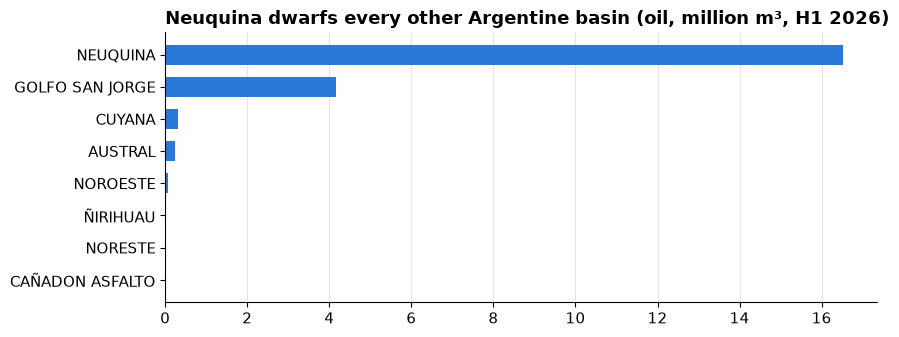

In [3]:
oil = frame[frame["product"] == "oil"]
by_basin = (oil.groupby("basin")["volume"].sum().sort_values())

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(by_basin.index, by_basin.values / 1e6, color=PALETTE[0], height=0.62)
ax.set_title("Neuquina dwarfs every other Argentine basin (oil, million m³, H1 2026)")
ax.grid(axis="y", visible=False)
fig.tight_layout()

## Monthly country totals

Again two panels — oil and gas live on different scales, so they never share
an axis.

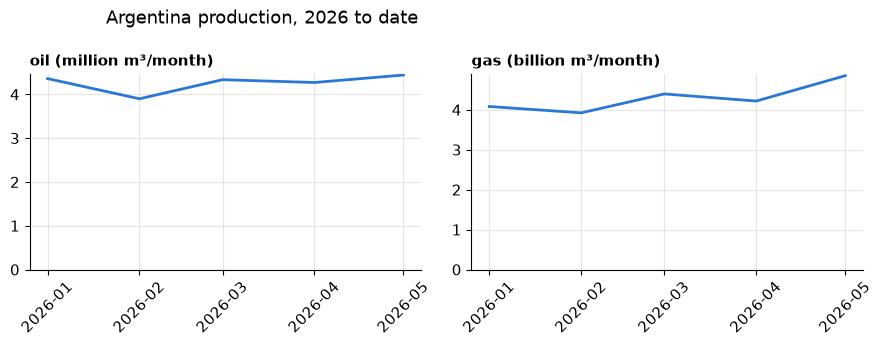

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, product, unit, scale in (
    (axes[0], "oil", "million m³/month", 1e6),
    (axes[1], "gas", "billion m³/month", 1e9),
):
    series = frame[frame["product"] == product]
    # the newest month is still being reported by operators — drop it
    monthly = (series.groupby("period")["volume"].sum() / scale).iloc[:-1]
    ax.plot(monthly.index, monthly.values)
    ax.set_title(f"{product} ({unit})", fontsize=11)
    ax.set_ylim(bottom=0)
    ax.set_xticks(monthly.index, [f"{p:%Y-%m}" for p in monthly.index], rotation=45)
fig.suptitle("Argentina production, 2026 to date", x=0.125, ha="left")
fig.tight_layout()

## Operators

`operator`, `field`, `region` all come normalized, so ranking is one groupby.

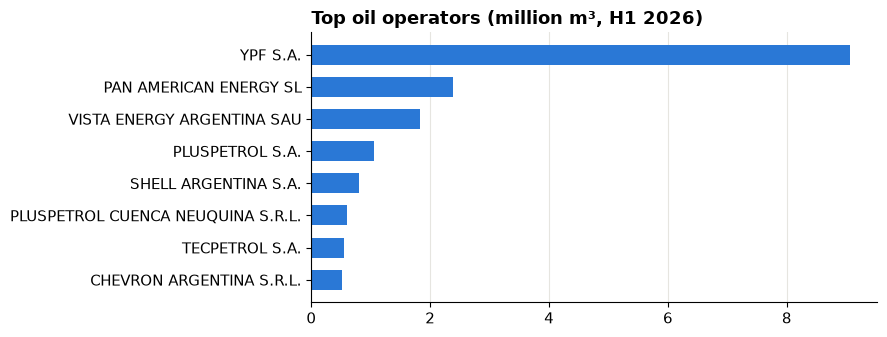

In [5]:
top = (oil.groupby("operator")["volume"].sum().nlargest(8).sort_values())

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(top.index, top.values / 1e6, color=PALETTE[0], height=0.62)
ax.set_title("Top oil operators (million m³, H1 2026)")
ax.grid(axis="y", visible=False)
fig.tight_layout()

Cross-source note: `schema.canonical_id` namespaces the source-native well IDs
(`"argentina:130589"`, `"anp:7-TPI-1-RJS"`) when you mix frames from several
regulators in one table.